In [ ]:
!pip install --upgrade matplotlib numpy==1.26.0 # need refresh enviroment after installation
!pip install basemap phik sweetviz

  Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
ERROR: Ignored the following yanked versions: 2.4.0
ERROR: Ignored the following versions that require a different python version: 1.21.2 Requires-Python >=3.7,<3.11; 1.21.3 Requires-Python >=3.7,<3.11; 1.21.4 Requires-Python >=3.7,<3.11; 1.21.5 Requires-Python >=3.7,<3.11; 1.21.6 Requires-Python >=3.7,<3.11; 1.26.0 Requires-Python <3.13,>=3.9; 1.26.1 Requires-Python <3.13,>=3.9
ERROR: Could not find a version that satisfies the requirement numpy==1.26.0 (from versions: 1.3.0, 1.4.1, 1.5.0, 1.5.1, 1.6.0, 1.6.1, 1.6.2, 1.7.0, 1.7.1, 1.7.2, 1.8.0, 1.8.1, 1.8.2, 1.9.0, 1.9.1, 1.9.2, 1.9.3, 1.10.0.post2, 1.10.1, 1.10.2, 1.10.4, 1.11.0, 1.11.1, 1.11.2, 1.11.3, 1.12.0, 1.12.1, 1.13.0, 1.13.1, 1.13.3, 1.14.0, 1.14.1, 1.14.2, 1.14.3, 1.14.4, 1.14.5, 1.14.6, 1.15.0, 1.15.1, 1.15.2, 1.15.3, 1.15.4, 1.16.0, 1.16.1, 1.16.2, 1.16.3, 1.16.4, 1.16.5, 1.16.6, 1.17.0, 1.17.1, 1.17.2, 1.17.3, 1.1

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

%matplotlib inline
sns.set_theme()
pd.set_option('display.max_columns', 100)

In [ ]:
sns.set_theme()

In [ ]:
path = '/content/drive/MyDrive/PhiUSIIL_Phishing_URL_Dataset.csv'
data = pd.read_csv(path)
data.shape

(235795, 56)

In [ ]:
data.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

In [ ]:
print('Пропусков всего:', data.isna().sum().sum())
print('Полных дубликатов строк:', data.duplicated().sum())
if 'URL' in data.columns:
    print('Дубликатов URL:', data['URL'].duplicated().sum())

Пропусков всего: 0
Полных дубликатов строк: 0
Дубликатов URL: 425


label
1    134850
0    100945
Name: count, dtype: int64
label
1    57.19
0    42.81
Name: count, dtype: float64


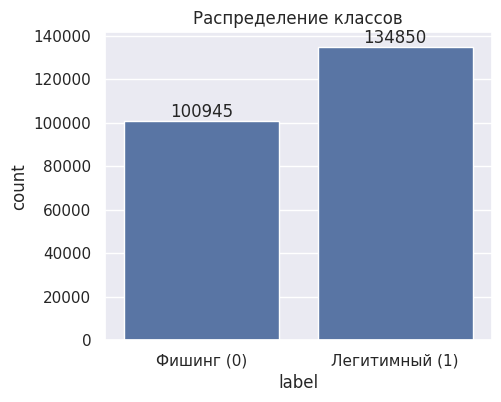

In [ ]:
target = 'label'   # 1 — легитимный, 0 — фишинг (по документации UCI)

counts = data[target].value_counts()
print(counts)
print((counts / len(data) * 100).round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=data[target], ax=ax)
ax.set_xticklabels(['Фишинг (0)', 'Легитимный (1)'])
ax.set_title('Распределение классов')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.show()

**Вывод:** классы примерно сбалансированы (около 57% / 43%), сильного дисбаланса нет.
Значит, accuracy не будет вводить в заблуждение, но для безопасности всё равно важны precision/recall по классу «фишинг».
Стратифицированное разбиение на train/test всё равно применим.

In [ ]:
text_cols = [c for c in ['FILENAME', 'URL', 'Domain', 'TLD', 'Title'] if c in data.columns]
feature_cols = [c for c in data.columns if c not in text_cols + [target]]

# бинарные признаки (0/1) и непрерывные/счётчики
binary_cols = [c for c in feature_cols if data[c].nunique() <= 2]
num_cols = [c for c in feature_cols if c not in binary_cols]

print('Текстовые:', text_cols)
print(f'Бинарные ({len(binary_cols)}):', binary_cols)
print(f'Числовые ({len(num_cols)}):', num_cols)

Текстовые: ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']
Бинарные (19): ['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo']
Числовые (31): ['URLLength', 'DomainLength', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'LineOfCode', 'LargestLineLength', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'NoOfPopup', 'NoOfiFrame', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [ ]:
data[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
NoOfObfuscatedChar,235795.0,0.024861,1.876249,0.000000,0.000000,0.000000,0.000000,4.470000e+02
ObfuscationRatio,235795.0,0.000138,0.003817,0.000000,0.000000,0.000000,0.000000,3.480000e-01


## Асимметрия распределений

In [ ]:
skew = data[num_cols].skew().sort_values(ascending=False)
skew.head(15)

,0
NoOfCSS,464.404031
NoOfObfuscatedChar,204.684335
NoOfJS,140.435761
NoOfEqualsInURL,114.985479
NoOfEmptyRef,106.826225
NoOfAmpersandInURL,106.717256
NoOfiFrame,97.677347
NoOfDegitsInURL,94.877574
NoOfPopup,84.952694
NoOfExternalRef,65.900247


## Текстовые признаки

In [ ]:
data[text_cols].describe()

,FILENAME,URL,Domain,TLD,Title
count,235795,235795,235795,235795,235795
unique,235795,235370,220086,695,197874
top,384822.txt,https://jauntyimprobableautomaticvectorization...,ipfs.io,com,0
freq,1,2,1197,112554,32719


**Вывод:** у большинства счётчиков (`NoOfImage`, `NoOfJS`, `LineOfCode`, `NoOfExternalRef` и др.)
сильная правая асимметрия и тяжёлые хвосты (медиана << максимум).
Для линейных моделей и kNN потребуется логарифмирование (`log1p`) и масштабирование; деревьям это не нужно.

## Анализ числовых признаков

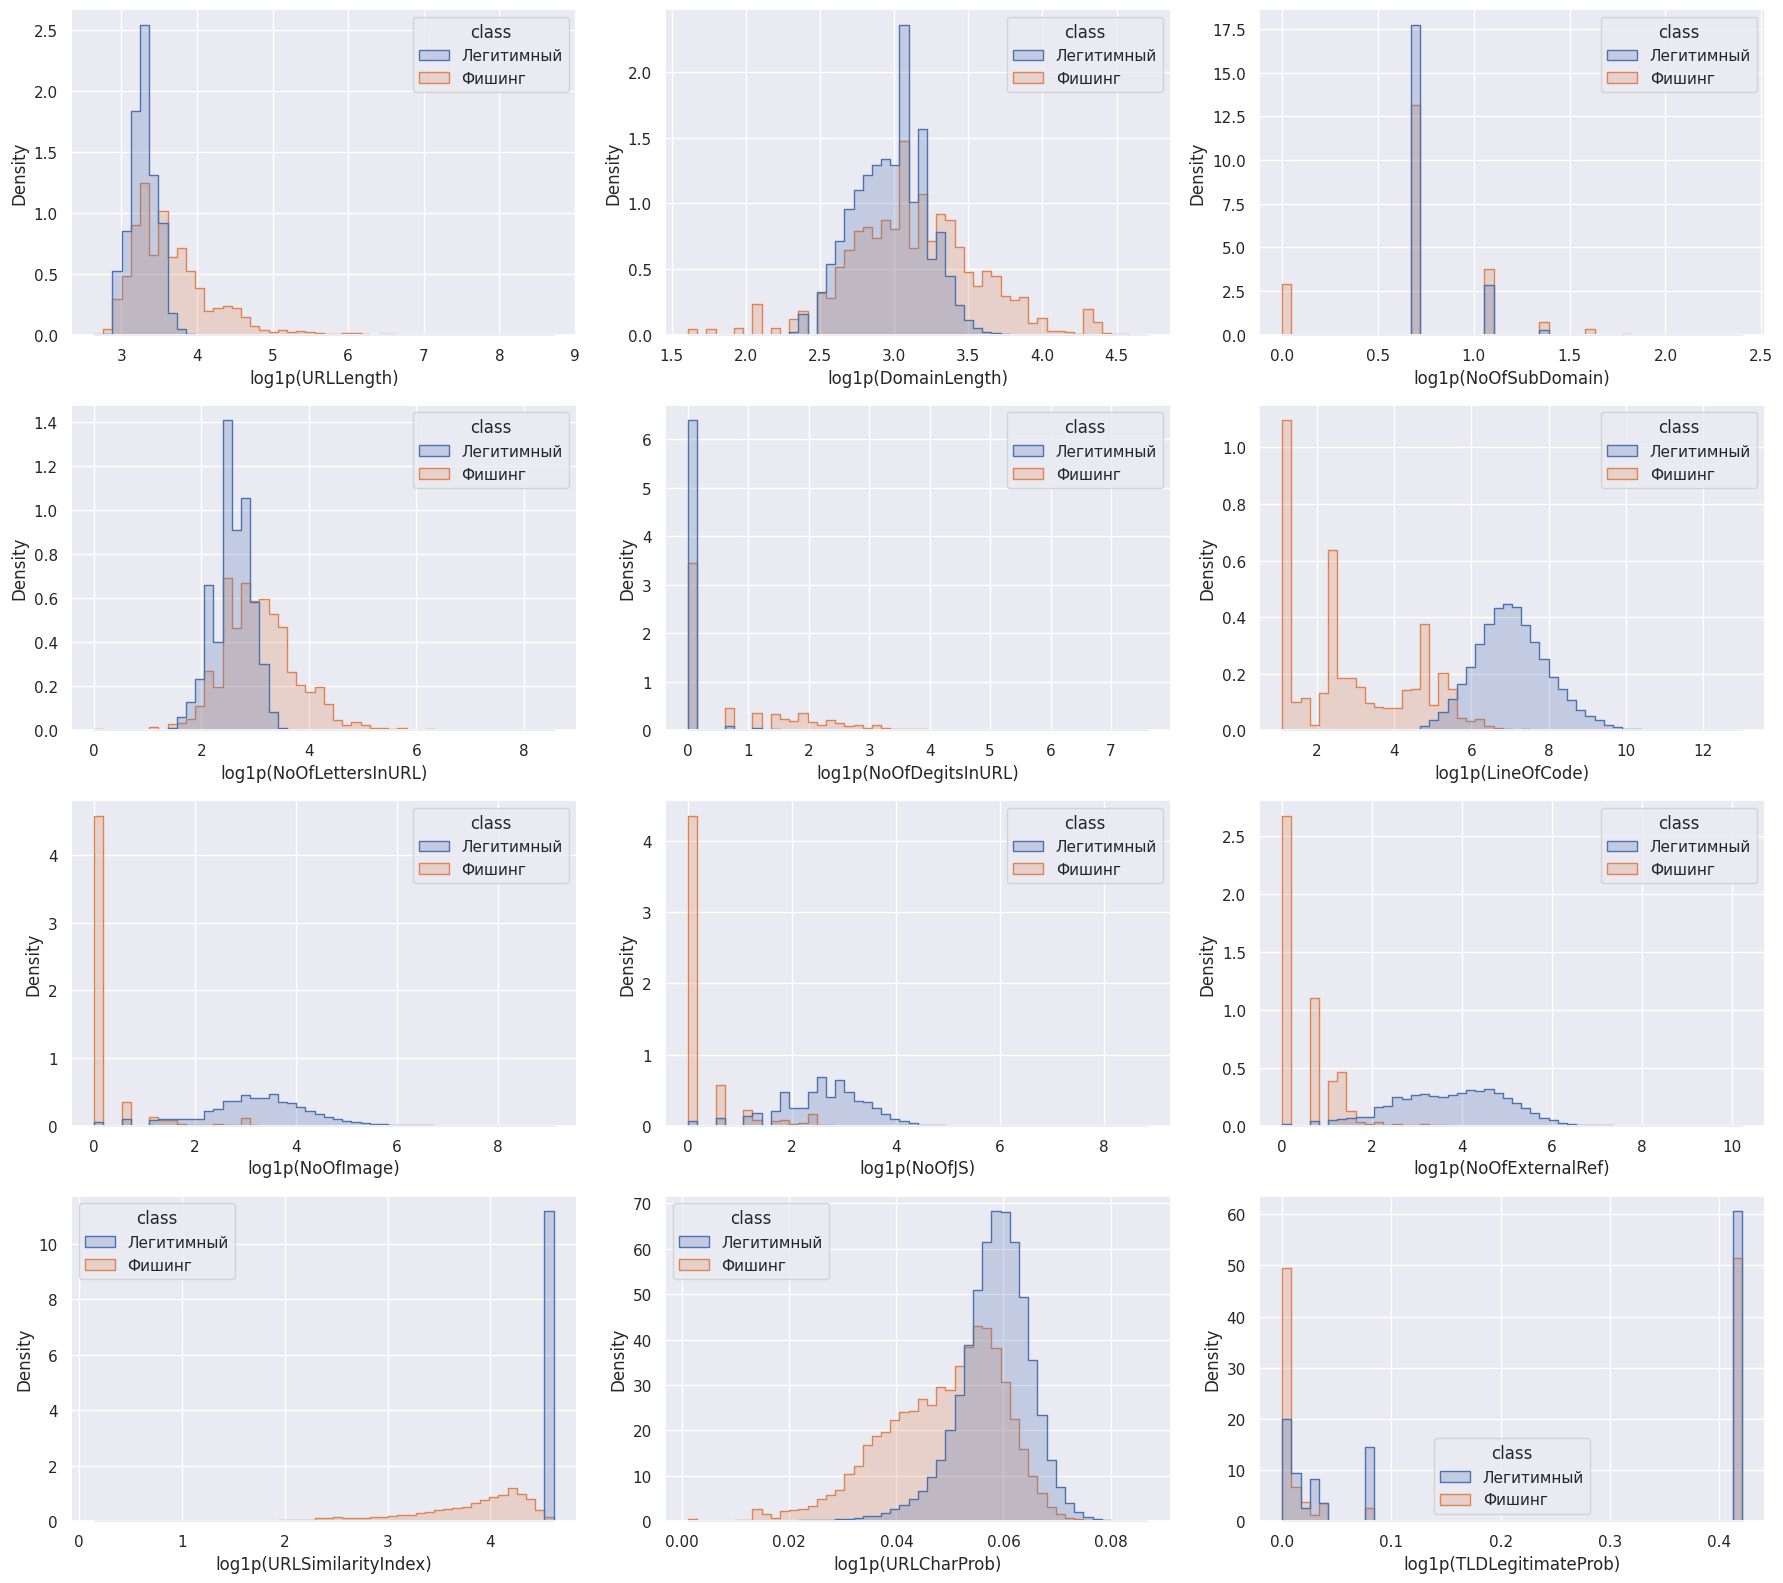

In [ ]:
key_num = [c for c in ['URLLength', 'DomainLength', 'NoOfSubDomain', 'NoOfLettersInURL',
                       'NoOfDegitsInURL', 'LineOfCode', 'NoOfImage', 'NoOfJS',
                       'NoOfExternalRef', 'URLSimilarityIndex', 'URLCharProb',
                       'TLDLegitimateProb'] if c in data.columns]

plot_df = data.copy()
plot_df['class'] = plot_df[target].map({0: 'Фишинг', 1: 'Легитимный'})

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
for ax, col in zip(axes.ravel(), key_num):
    sns.histplot(data=plot_df, x=np.log1p(plot_df[col].clip(lower=0)), hue='class',
                 bins=50, stat='density', common_norm=False, element='step', ax=ax)
    ax.set_xlabel(f'log1p({col})')
plt.tight_layout()
plt.show()

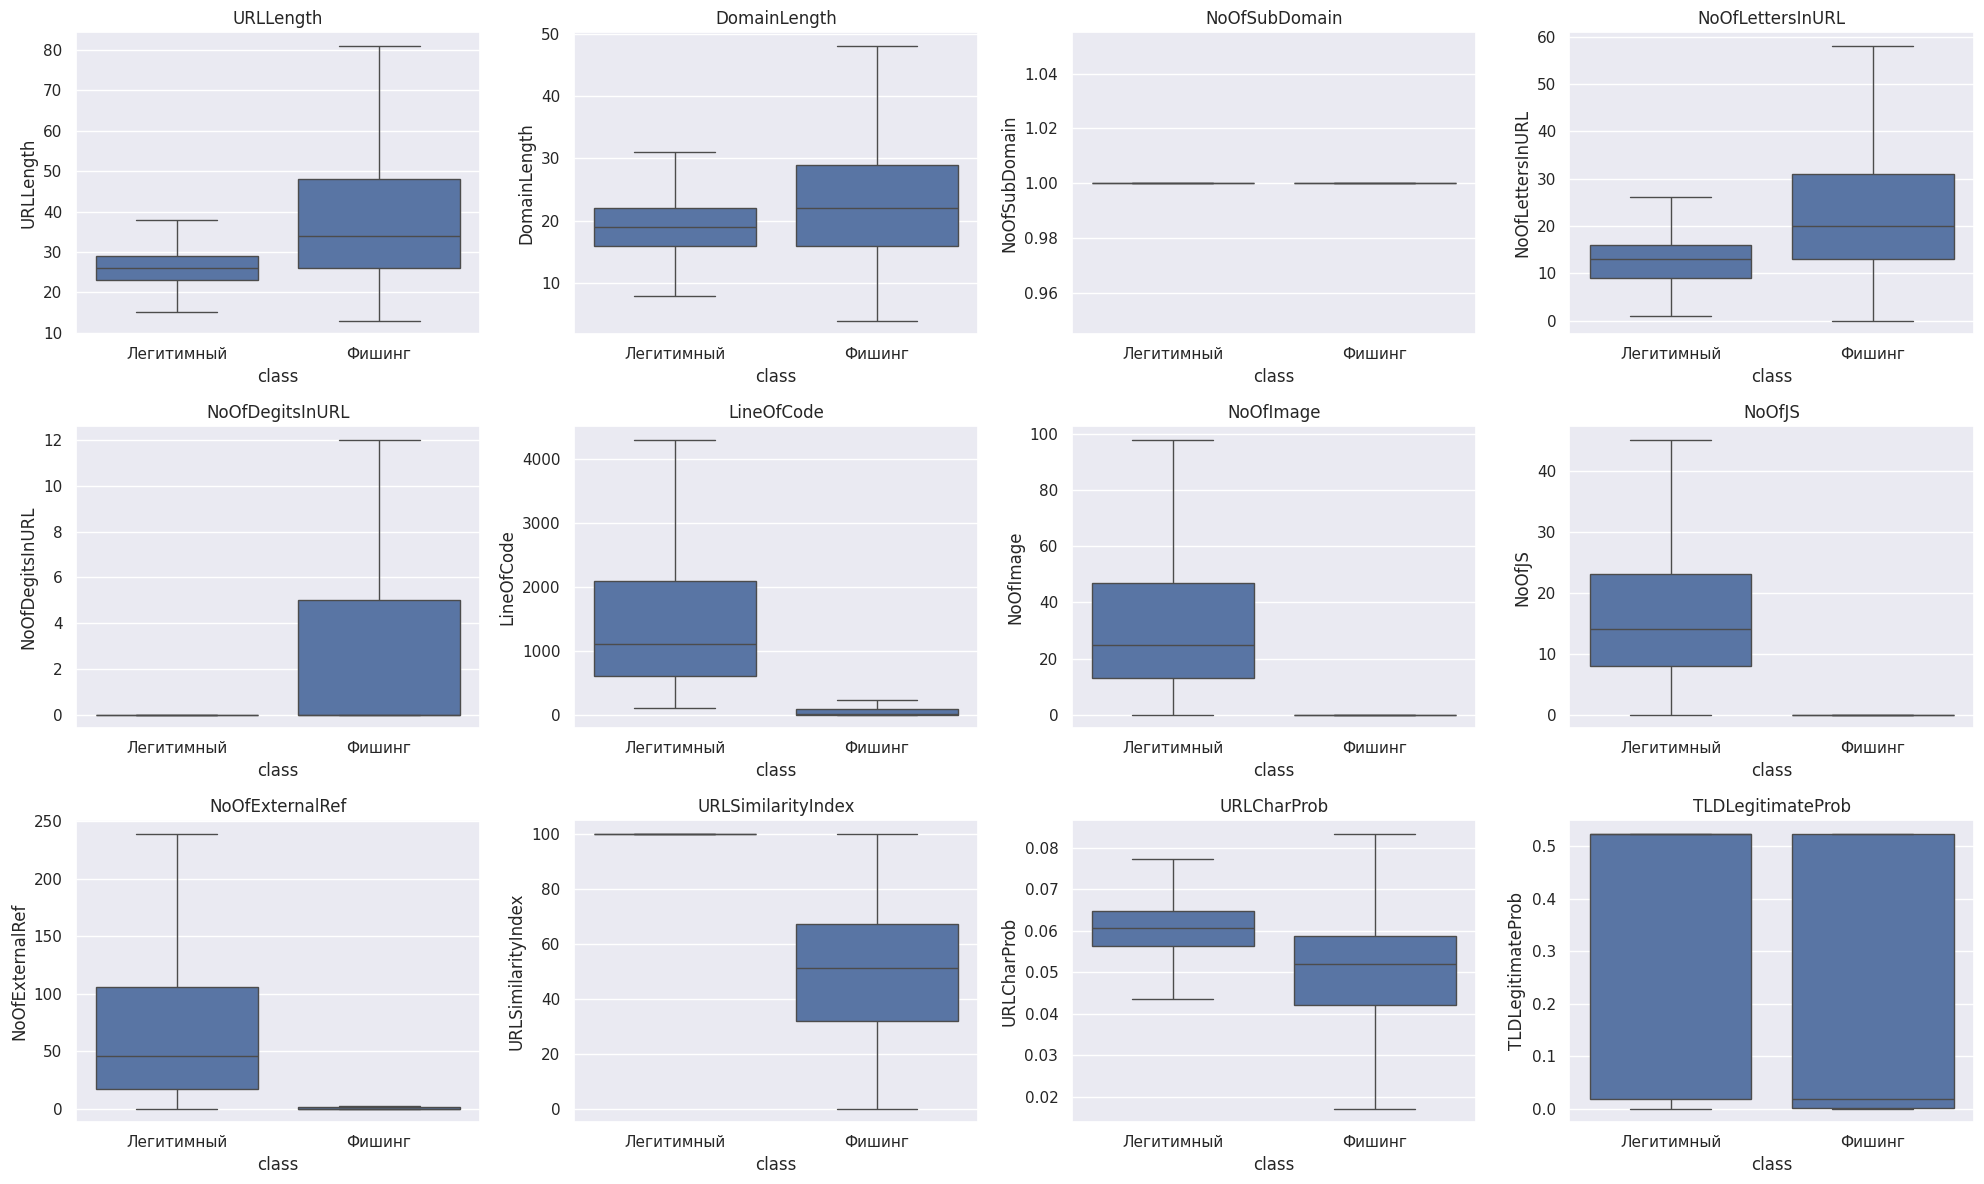

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), key_num):
    sns.boxplot(data=plot_df, x='class', y=col, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
def count_outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outliers = pd.DataFrame({
    'n_outliers': {c: count_outliers_iqr(data[c]) for c in num_cols}
})
outliers['share_%'] = (outliers['n_outliers'] / len(data) * 100).round(2)
outliers.sort_values('share_%', ascending=False).head(15)

,n_outliers,share_%
NoOfSubDomain,57389,24.34
NoOfDegitsInURL,51461,21.82
DegitRatioInURL,51461,21.82
NoOfEmptyRef,38885,16.49
NoOfiFrame,34441,14.61
NoOfExternalRef,22780,9.66
URLLength,22493,9.54
NoOfLettersInURL,19662,8.34
LineOfCode,19280,8.18
NoOfImage,18362,7.79


**Вывод:** фишинговые страницы заметно отличаются по структуре: у них меньше кода,
картинок, JS и внешних ссылок (страницы-«заглушки»), а `URLSimilarityIndex` и `TLDLegitimateProb` ниже.
Выбросов много, потому что у крупных легитимных порталов тысячи строк кода и ссылок.

## Бинарные признаки

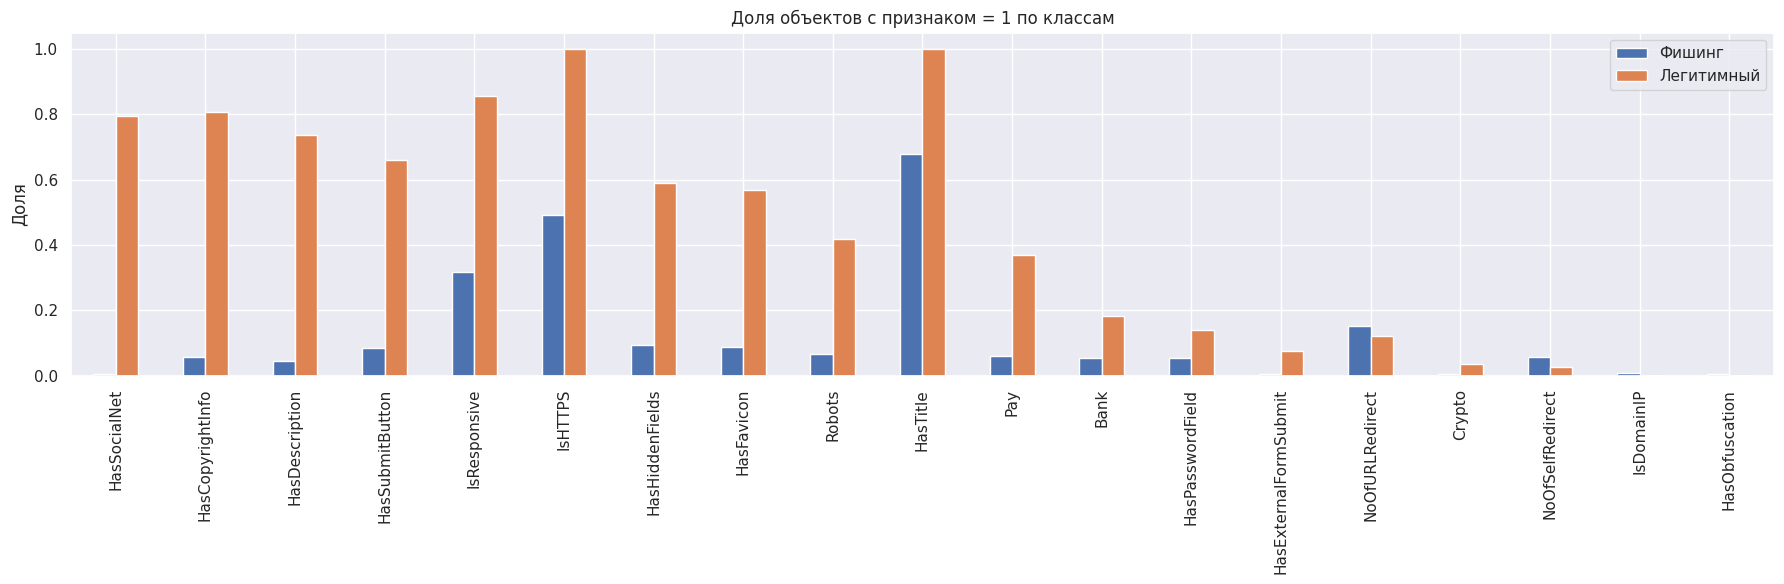

,Фишинг,Легитимный,diff
HasSocialNet,0.005062,0.794557,0.789495
HasCopyrightInfo,0.057338,0.808239,0.750901
HasDescription,0.044163,0.736633,0.692471
HasSubmitButton,0.084898,0.660882,0.575985
IsResponsive,0.317460,0.854364,0.536904
IsHTTPS,0.492238,1.000000,0.507762
HasHiddenFields,0.093279,0.590782,0.497504
HasFavicon,0.087572,0.567023,0.479450
Robots,0.065897,0.416737,0.350840
HasTitle,0.677587,0.998754,0.321167


In [ ]:
# Доля единиц признака в каждом классе
bin_stats = data.groupby(target)[binary_cols].mean().T
bin_stats.columns = ['Фишинг', 'Легитимный']
bin_stats['diff'] = (bin_stats['Легитимный'] - bin_stats['Фишинг']).abs()
bin_stats = bin_stats.sort_values('diff', ascending=False)

bin_stats[['Фишинг', 'Легитимный']].plot(kind='bar', figsize=(18, 6))
plt.title('Доля объектов с признаком = 1 по классам')
plt.ylabel('Доля')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

bin_stats.head(10)

**Вывод:** признаки вроде `HasSocialNet`, `HasCopyrightInfo`, `HasDescription`, `HasFavicon`, `IsResponsive`
сильно различаются между классами (у легитимных чаще).
Часть бинарных признаков (`IsDomainIP`, `HasObfuscation`) очень редкая - они информативны лишь для узкой группы объектов.

## Категориальные признаки: TLD

Уникальных TLD: 695


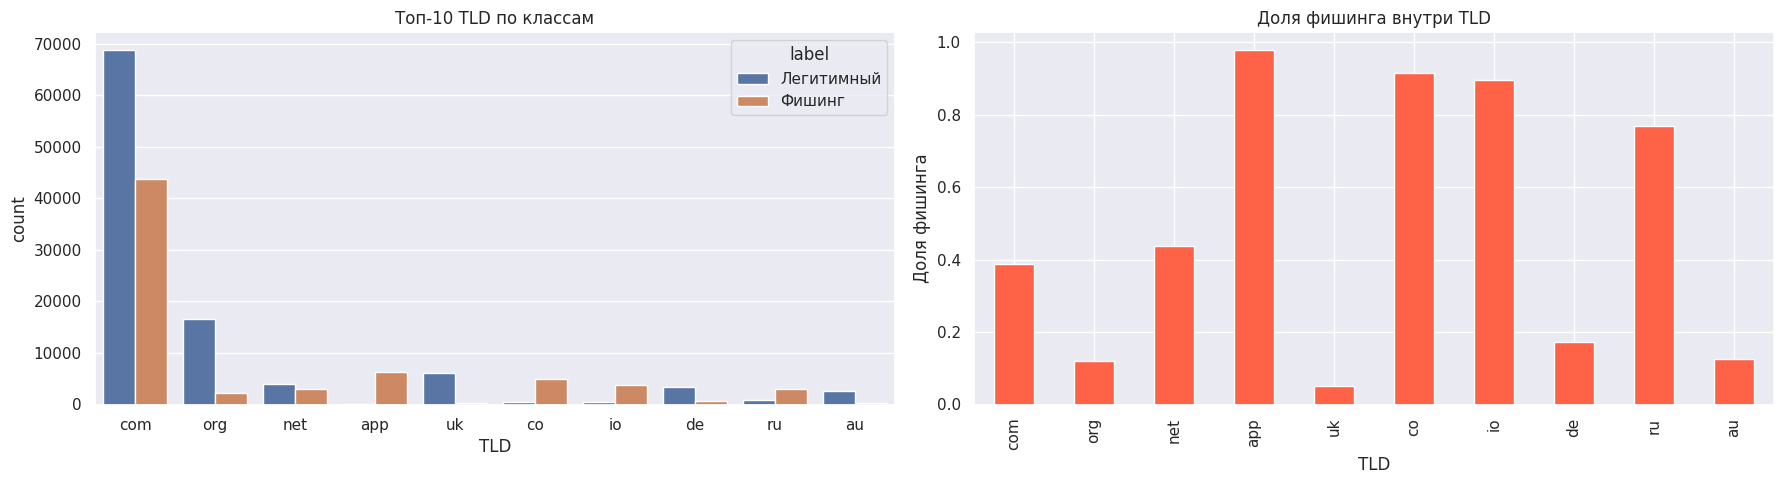

In [ ]:

if 'TLD' in data.columns:
    print('Уникальных TLD:', data['TLD'].nunique())

    top_tld = data['TLD'].value_counts().head(10).index
    tld_df = data[data['TLD'].isin(top_tld)]

    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    sns.countplot(data=tld_df, x='TLD', hue=tld_df[target].map({0: 'Фишинг', 1: 'Легитимный'}),
                  order=top_tld, ax=axes[0])
    axes[0].set_title('Топ-10 TLD по классам')

    phish_share = tld_df.groupby('TLD')[target].apply(lambda s: (s == 0).mean()).loc[top_tld]
    phish_share.plot(kind='bar', ax=axes[1], color='tomato')
    axes[1].set_title('Доля фишинга внутри TLD')
    axes[1].set_ylabel('Доля фишинга')
    plt.tight_layout()
    plt.show()

**Вывод:** TLD имеет сотни уникальных значений с длинным хвостом, поэтому one-hot кодирование раздует
пространство признаков. Лучше использовать частотное кодирование или target encoding (внутри кросс-валидации, чтобы не было утечки).
В датасете уже есть `TLDLegitimateProb`, который является таким закодированным признаком.

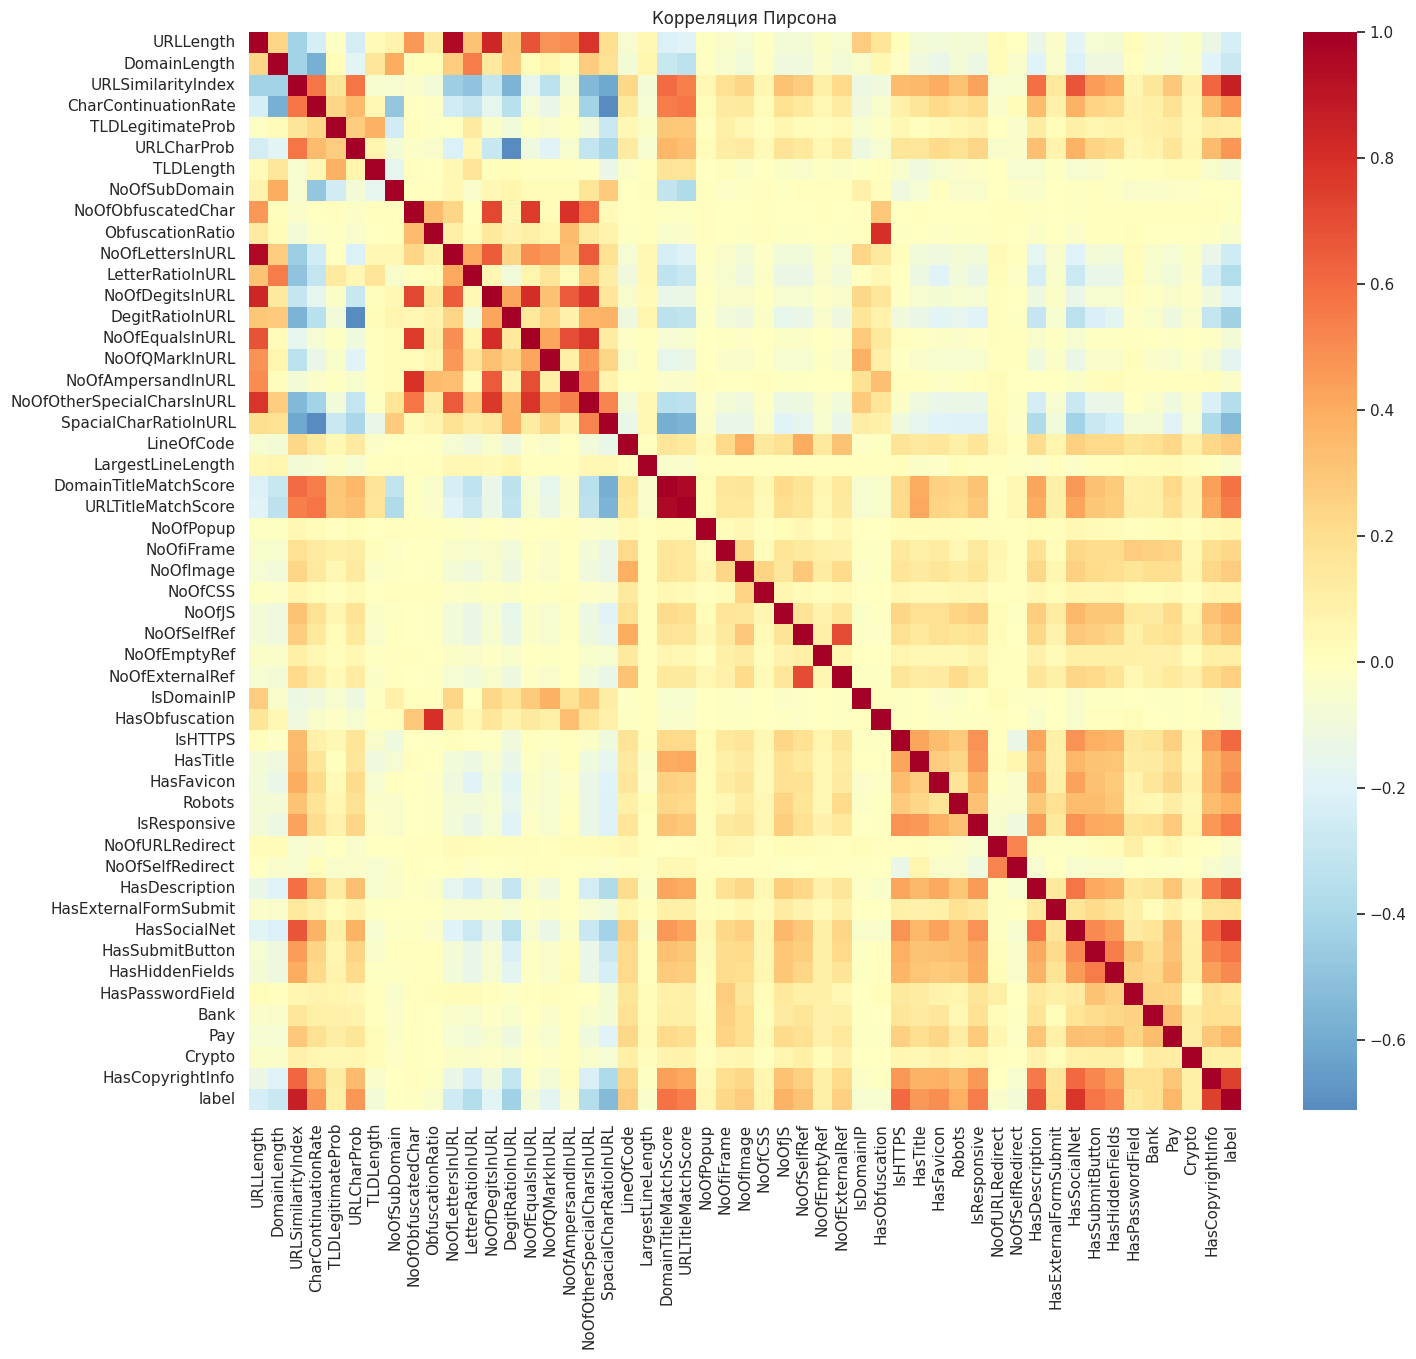

In [ ]:
#Корреляции
corr = data[num_cols + binary_cols + [target]].corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap='RdYlBu_r', center=0, annot=False)
plt.title('Корреляция Пирсона')
plt.show()

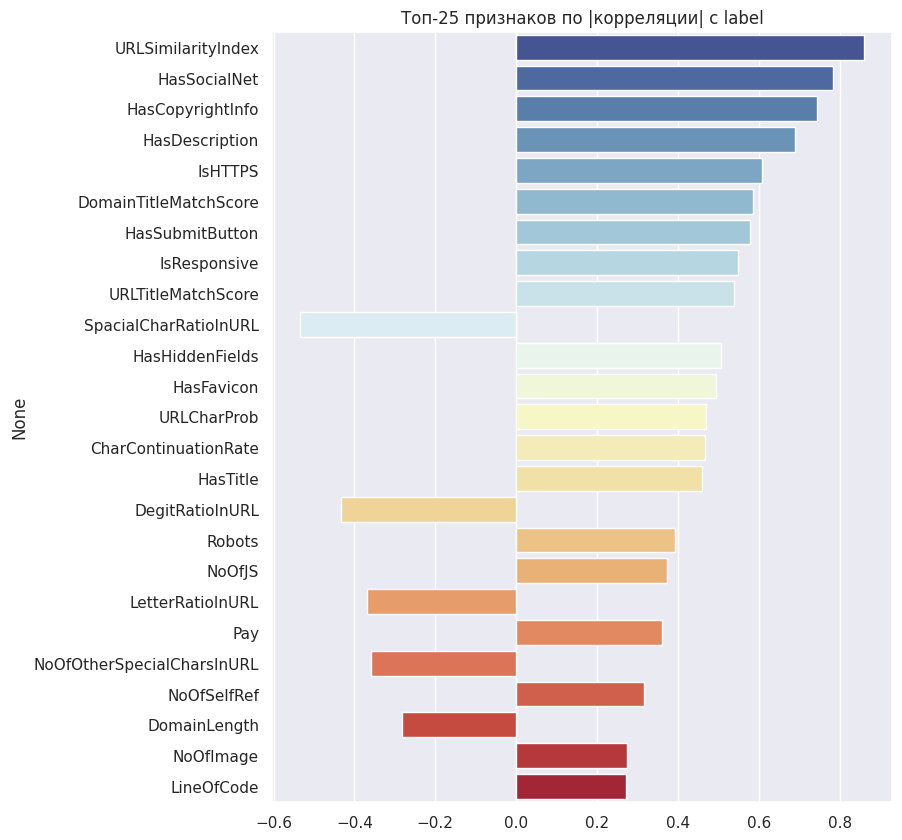

In [ ]:
# Корреляция с целевой переменной
target_corr = corr[target].drop(target).sort_values(key=abs, ascending=False)

plt.figure(figsize=(8, 10))
sns.barplot(x=target_corr.head(25).values, y=target_corr.head(25).index, palette='RdYlBu_r')
plt.title('Топ-25 признаков по |корреляции| с label')
plt.show()

In [ ]:
# Пары сильно коррелирующих признаков (мультиколлинеарность)
upper = corr.drop(target).drop(columns=target).where(
    np.triu(np.ones((len(corr) - 1, len(corr) - 1)), k=1).astype(bool))
pairs = upper.stack().rename('corr').reset_index()
pairs = pairs[pairs['corr'].abs() > 0.9].sort_values('corr', key=abs, ascending=False)
pairs.head(15)

,level_0,level_1,corr
819,DomainTitleMatchScore,URLTitleMatchScore,0.961008
9,URLLength,NoOfLettersInURL,0.956047


**Вывод:** есть группы почти дублирующих друг друга признаков (например, `NoOfLettersInURL` и `URLLength`,
`NoOfSelfRef` и `LineOfCode`).
Пирсон измеряет только линейную связь и чувствителен к выбросам, поэтому дополнительно надо посмотреть одиночную предсказательную силу признаков.

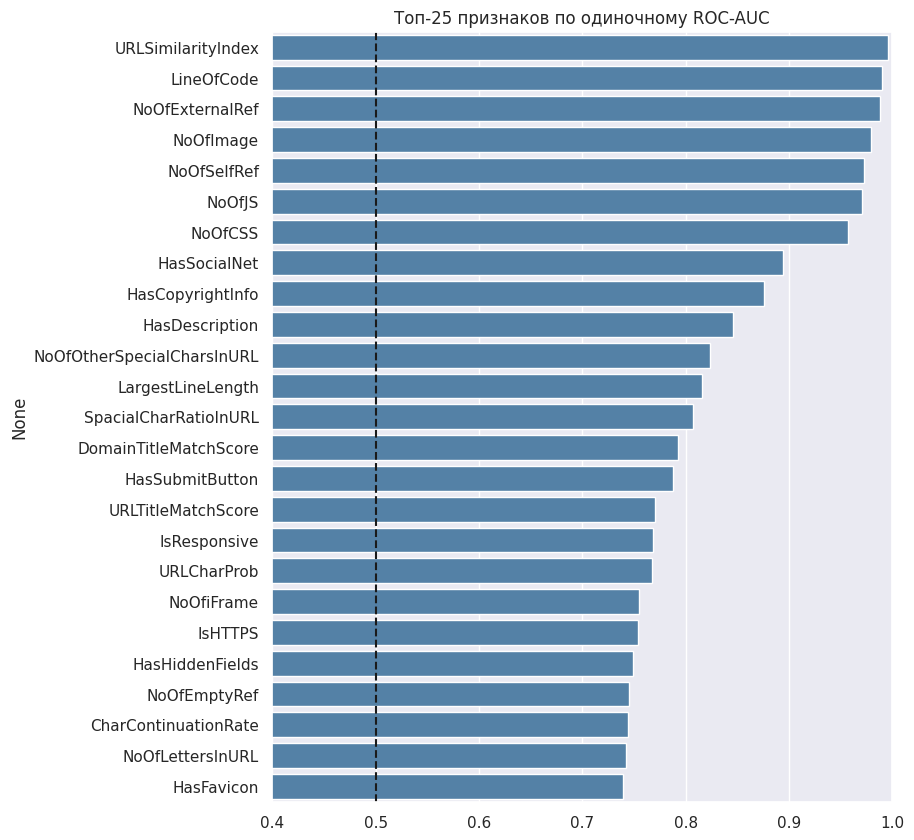

,0
URLSimilarityIndex,0.996107
LineOfCode,0.990255
NoOfExternalRef,0.988021
NoOfImage,0.979635
NoOfSelfRef,0.972456
NoOfJS,0.970823
NoOfCSS,0.957596
HasSocialNet,0.894747
HasCopyrightInfo,0.875450
HasDescription,0.846235


In [ ]:
# ROC-AUC каждого признака по отдельности
auc = {}
for c in num_cols + binary_cols:
    a = roc_auc_score(data[target], data[c])
    auc[c] = max(a, 1 - a)
auc = pd.Series(auc).sort_values(ascending=False)

plt.figure(figsize=(8, 10))
sns.barplot(x=auc.head(25).values, y=auc.head(25).index, color='steelblue')
plt.axvline(0.5, color='k', ls='--')
plt.xlim(0.4, 1.0)
plt.title('Топ-25 признаков по одиночному ROC-AUC')
plt.show()

auc.head(10)

**Вывод:** несколько признаков (`URLSimilarityIndex`, `HasSocialNet`, `HasCopyrightInfo`, `LineOfCode` и др.)
дают AUC > 0.9 поодиночке. Это значит, что задача решается довольно легко, и на тесте можно ожидать очень высоких метрик.

Объяснённая дисперсия: [0.282 0.098]


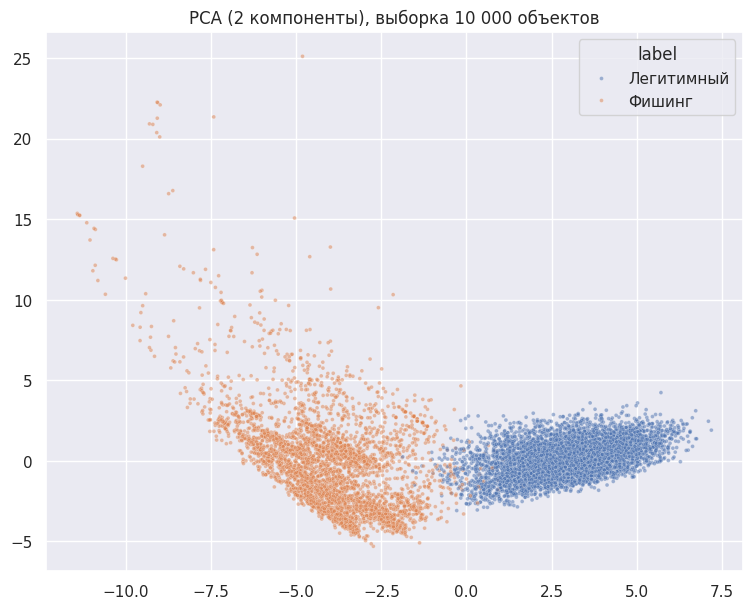

In [ ]:
## Визуализация в пространстве PCA
sample = data.sample(10000, random_state=42)
X = np.log1p(sample[num_cols].clip(lower=0))
X = pd.concat([X, sample[binary_cols]], axis=1)
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
print('Объяснённая дисперсия:', pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(9, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1],
                hue=sample[target].map({0: 'Фишинг', 1: 'Легитимный'}),
                s=8, alpha=0.5)
plt.title('PCA (2 компоненты), выборка 10 000 объектов')
plt.show()

**Вывод:** классы в 2D-проекции разделяются хорошо, но с областью перекрытия.


## Итоги EDA

### 1. Общая характеристика данных
- Объём: 235 795 объектов, 56 признаков. Пропусков нет, полных дубликатов строк: нет, дубликатов URL: 425.
- Классы: фишинг — 47%, легитимные — 53%. Дисбаланс умеренный, но в реальном трафике фишинг встречается намного реже, поэтому оценивать модель по accuracy нельзя.
- Типы признаков: 31 числовых счётчиков и характеристик, 19 бинарных флагов, 5 текстовых столбцов (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`), которые в модель напрямую не подаются.

### 2. Распределения признаков
- **Асимметрия.** У 15 из 31 числовых признаков |skew| > 1. Самые «тяжёлые»: `NoOfCSS` (skew ≈ 464,4), `NoOfObfuscatedChar` (≈ 204,7), `NoOfJS` (≈ 140,4). У `NoOfCSS` максимум 35 820 при медиане 2 — в 17 910 раз больше медианы, т.е. типичное значение и экстремальное отличаются на порядки.
- **Выбросы.** По правилу IQR у 5 признаков доля выбросов превышает 10% (максимум — 24,34% у `NoOfSubDomain`). Это не ошибки измерения, а реальные объекты: крупные порталы с тысячами строк кода и ссылок. Удалять их нельзя, иначе потеряем легитимный класс «больших сайтов».
- **Различия между классами.** На графиках в log-шкале у фишинга распределения `LineOfCode`, `NoOfJS`, `NoOfImage`, `NoOfExternalRef` сдвинуты влево (страницы-заглушки с минимумом контента), у легитимных они смещены вправо и имеют длинный хвост. По `URLLength` и `NoOfSubDomain` различия слабее, и распределения сильно перекрываются.
- **Бинарные признаки.** Различия по флагам `HasSocialNet`, `HasCopyrightInfo`, `HasDescription`, `HasFavicon`, `IsResponsive` велики: у легитимных они встречаются в 56,7–85,4% случаев, у фишинга только в 0,5–31,7%. Например, `HasSocialNet` — 79,5% против 0,5%, `HasCopyrightInfo` — 80,8% против 5,7%, `HasDescription` — 73,7% против 4,4%. Признаки `IsDomainIP`, `HasObfuscation` и др. встречаются менее чем в 1% случаев, поэтому для модели их вклад будет ограничен.
- **TLD.** 695 уникальных значений, распределение с длинным хвостом: топ-10 TLD покрывают не менее 47,7% объектов (только com — 112 554 объекта, 47,7%; точная сумма по топ-10 в ноутбуке не выведена). Доля фишинга сильно зависит от TLD (на графике — от единиц процентов до >80%; точные значения не напечатаны), т.е. признак информативен, но требует аккуратного кодирования.

### 3. Информативность признаков
- **Одиночный ROC-AUC.** 7 признаков дают AUC > 0,9 поодиночке; точное число признаков с AUC > 0,7 и число признаков с AUC < 0,55 в ноутбуке не выводилось. Лидеры: `URLSimilarityIndex` (AUC ≈ 0,996), `LineOfCode` (≈ 0,990), `NoOfExternalRef` (≈ 0,988).
- **Корреляция с целью.** Численные значения |r| с label в ноутбуке не напечатаны; по одиночному AUC лидируют `URLSimilarityIndex`, `LineOfCode`, `NoOfExternalRef`, `NoOfImage`, `NoOfSelfRef`, `NoOfJS`, `NoOfCSS`. Взаимная информация в ноутбуке не рассчитывалась. Значит, ограничиваться корреляцией Пирсона нельзя.
- **Мультиколлинеарность.** Найдено 2 пары признаков с |r| > 0,9: `DomainTitleMatchScore` – `URLTitleMatchScore` (0,961) и `URLLength` – `NoOfLettersInURL` (0,956). Для линейных моделей их нужно прореживать, деревьям это не мешает.
- **Разделимость.** В проекции PCA (2 компоненты объясняют 38,0% дисперсии: 28,2% + 9,8%) классы в основном разделяются, область перекрытия небольшая. Вывод: даже простые модели покажут высокое качество, а сложные нужны для пограничных случаев.

### 4. Риски и проблемы
1. **Утечка и завышенные метрики.** Признаки `URLSimilarityIndex`, `*Prob` (в т.ч. `TLDLegitimateProb`) рассчитаны авторами датасета по всей выборке, а AUC отдельных признаков близок к 1. Модель нужно сравнивать с этими признаками и без них.
2. **Дубликаты URL** нужно удалить до разбиения на train/test.
3. **Высокая кардинальность `TLD`**: one-hot раздует пространство, нужны частотное кодирование или target encoding внутри кросс-валидации.
4. **Дрейф данных.** Фишинг быстро меняется, поэтому реальное качество на новых данных будет ниже, чем на тесте. Для финальной проверки лучше разбивать данные по времени, если есть такая возможность.

### 5. План предобработки
- удалить идентификаторы и текстовые поля (`FILENAME`, `URL`, `Domain`, `Title`), закодировать `TLD`;
- для линейных моделей и kNN: `log1p` к счётчикам и `StandardScaler`, прореживание коррелированных признаков; для деревьев и бустинга достаточно сырых значений;
- стратифицированное разбиение, подбор порога по precision-recall кривой;
- метрики: Recall по классу «фишинг» (`pos_label=0`), Precision и FPR.